# L7 Hackathon

# Libraries

In [ ]:
# It's good practice to add comments to explain your code
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder

# Exploratory Data Analysis – Understanding the Dataset

* Think about possible biases and limitations of this dataset.
* What are the sources of uncertainty?
* What is the format of feature values?
* What is the statistics of these feature values? How many symptoms are reported or not?
* Which symptoms have a reporting bias, i.e., likely to be reported when the patient is COVID positive?
* How will the symptoms with reporting bias affect the model’s performance?
* Visualization: Draw the bar graph of features grouped by the target class?
* What does the bar graph of the symptoms with reporting bias look like?
* Determine if we have a class imbalance in the dataset? If so, what do you reckon will be the downstream challenges in evaluating the model? How will you overcome those challenges?

In [ ]:
# Add your code here
df = pd.read_csv('corona_tested_individuals_ver_006.english.csv')
df.head()

/tmp/ipykernel_797/2393272375.py:2: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('corona_tested_individuals_ver_006.english.csv')


,test_date,cough,fever,sore_throat,shortness_of_breath,head_ache,corona_result,age_60_and_above,gender,test_indication
0,2020-04-30,0.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
1,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
2,2020-04-30,0.0,1.0,0.0,0.0,0.0,negative,NaN,male,Other
3,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
4,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,male,Other


In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

corona_result
negative    260227
positive     14729
other         3892
Name: count, dtype: int64
corona_result
negative    93.322168
positive     5.282089
other        1.395742
Name: proportion, dtype: float64


<Axes: xlabel='corona_result'>

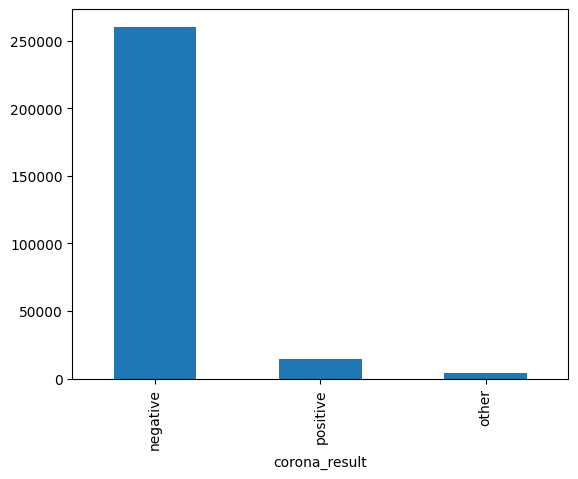

In [ ]:
'''Take a look at the data'''

# Count the different COVID-19 test results
print(df['corona_result'].value_counts(dropna=False))

# Calculate the percentage of each result
print(df['corona_result'].value_counts(normalize=True, dropna=False) * 100)

# Visualise the distribution
df['corona_result'].value_counts().plot(kind='bar')


In [ ]:
#Investigate the mixed types on col 7
print(df['age_60_and_above'].value_counts(dropna=False))

age_60_and_above
NaN    127320
No     125703
Yes     25825
Name: count, dtype: int64


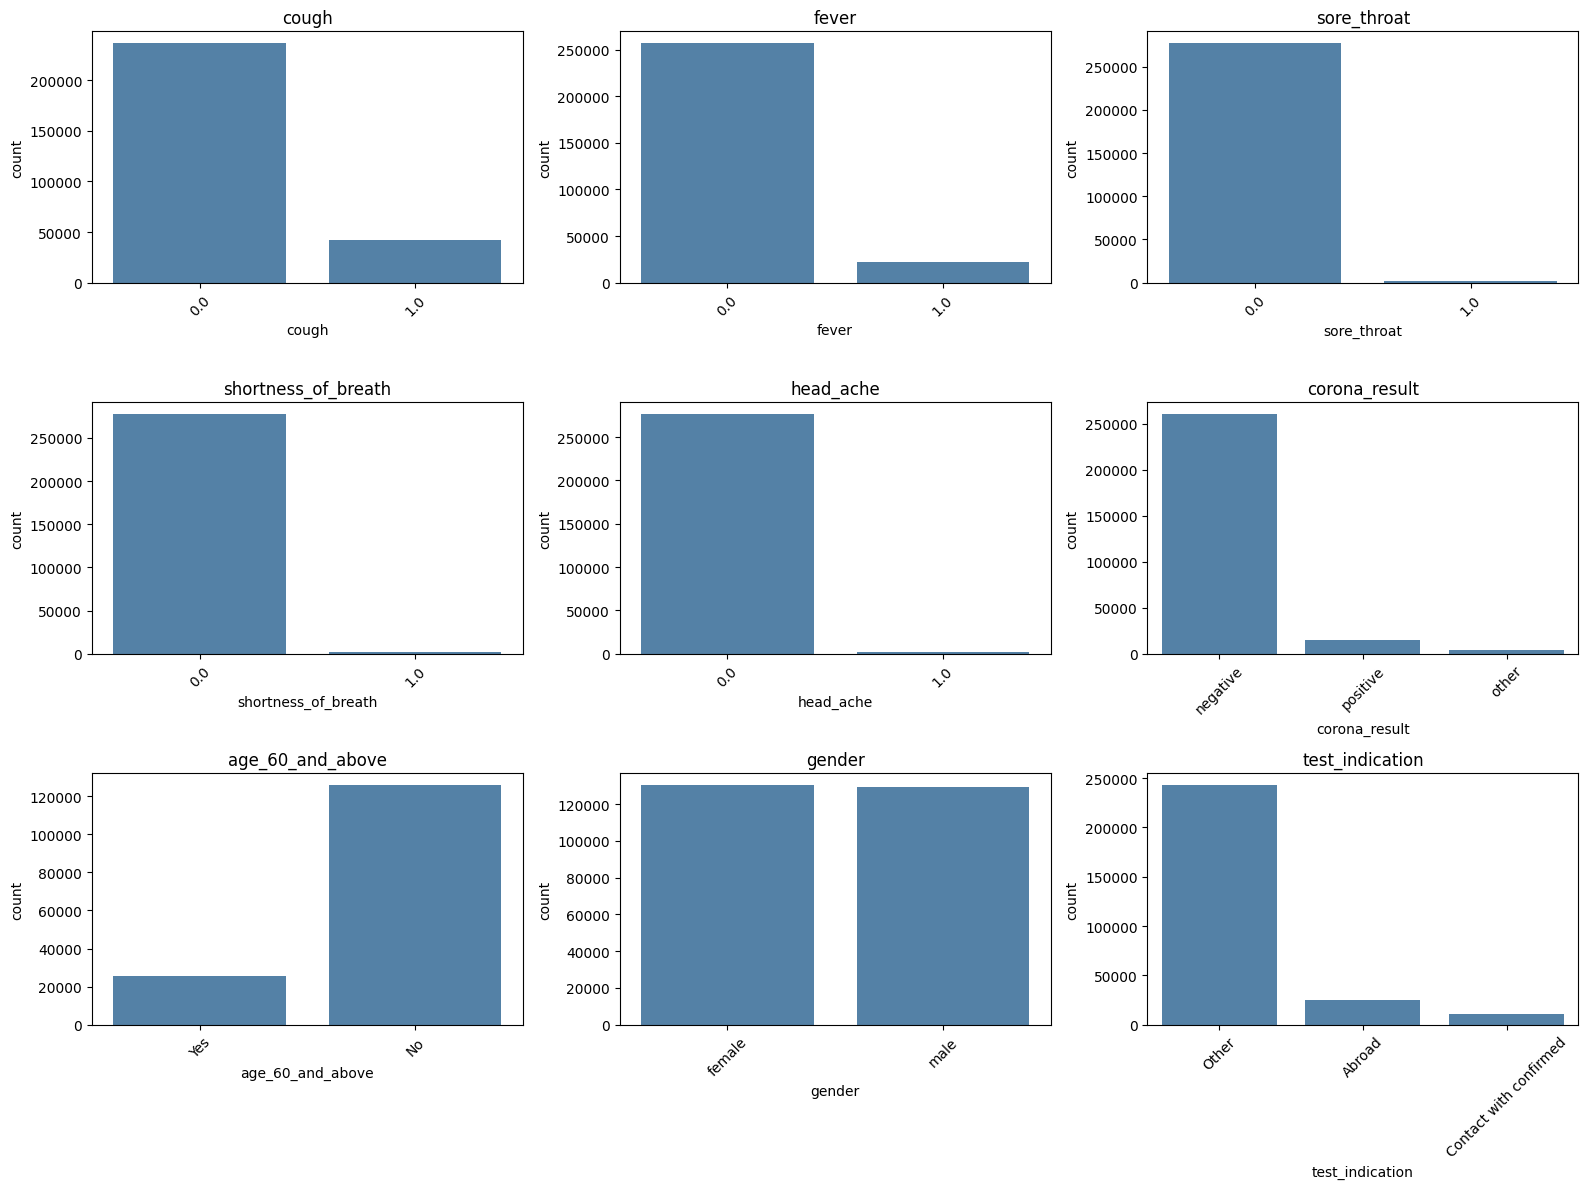

In [ ]:
'''Look at all features'''

# Create a copy for exploration
eda_df = df.copy()

# Exclude test_date for now
columns = eda_df.columns.drop('test_date')

# Create a grid of charts
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(columns):
    sns.countplot(
        data=eda_df,
        x=col,
        ax=axes[i],
        color='steelblue'
    )
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


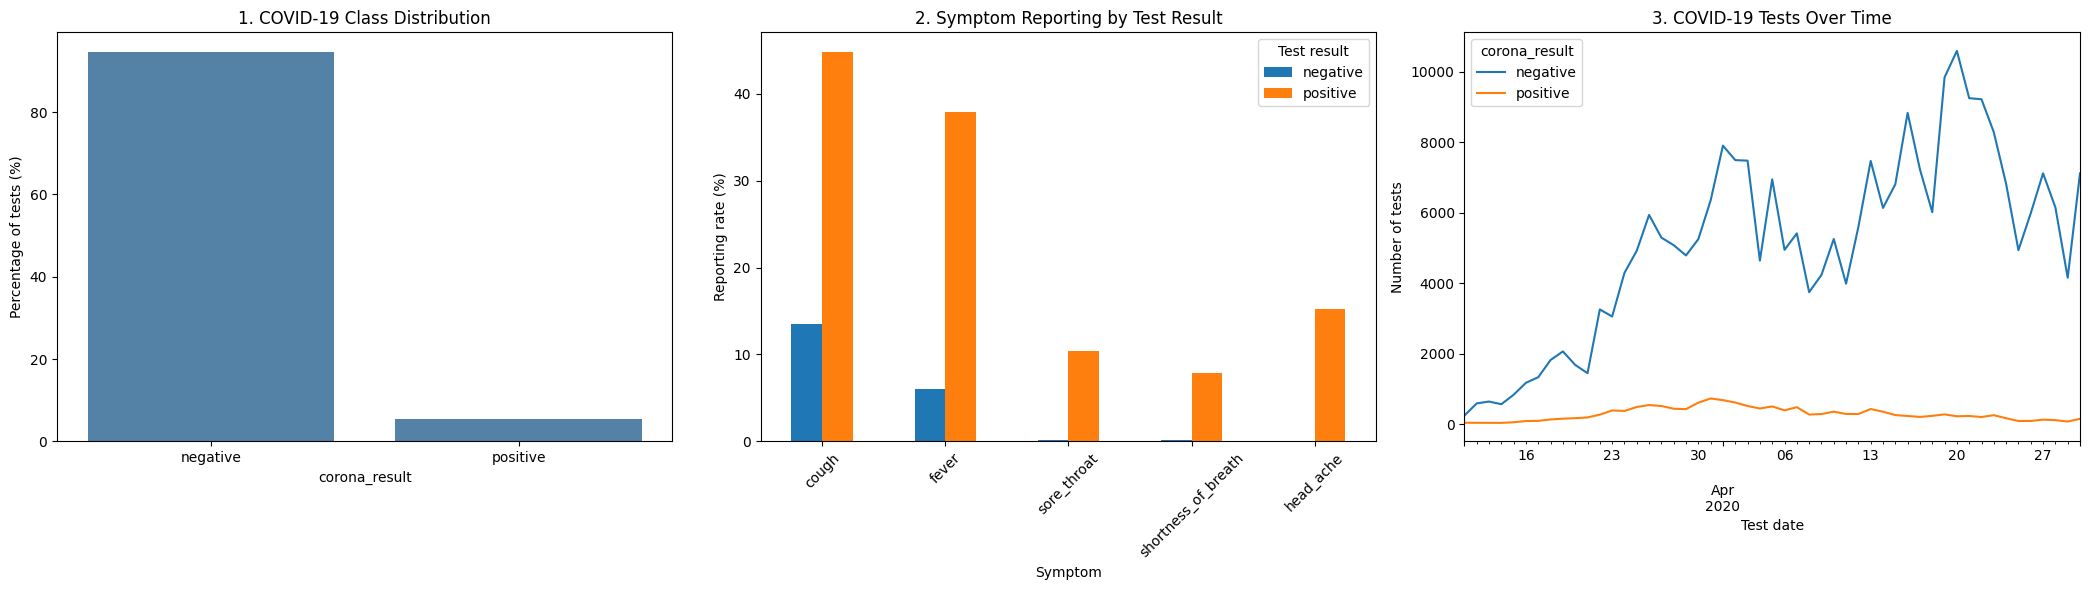

In [ ]:
''''''

# Keep only confirmed positive and negative results
plot_df = df[
    df['corona_result'].isin(['positive', 'negative'])
].copy()

symptoms = [
    'cough', 'fever', 'sore_throat',
    'shortness_of_breath', 'head_ache'
]

# Convert symptoms to numeric values
for symptom in symptoms:
    plot_df[symptom] = pd.to_numeric(
        plot_df[symptom], errors='coerce'
    )

# Create three charts
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# 1. Class distribution
class_pct = (
    plot_df['corona_result']
    .value_counts(normalize=True)
    .reindex(['negative', 'positive']) * 100
)

sns.barplot(
    x=class_pct.index,
    y=class_pct.values,
    ax=axes[0],
    color='steelblue'
)
axes[0].set_title('1. COVID-19 Class Distribution')
axes[0].set_ylabel('Percentage of tests (%)')

# 2. Symptoms grouped by test result
symptom_rates = (
    plot_df.groupby('corona_result')[symptoms]
    .mean()
    .T
    .mul(100)
)

symptom_rates.plot(
    kind='bar',
    ax=axes[1]
)
axes[1].set_title('2. Symptom Reporting by Test Result')
axes[1].set_ylabel('Reporting rate (%)')
axes[1].set_xlabel('Symptom')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Test result')

# 3. Testing patterns over time
plot_df['test_date'] = pd.to_datetime(
    plot_df['test_date'], errors='coerce'
)

daily = (
    plot_df.groupby(['test_date', 'corona_result'])
    .size()
    .unstack(fill_value=0)
)

daily.plot(
    ax=axes[2]
)
axes[2].set_title('3. COVID-19 Tests Over Time')
axes[2].set_ylabel('Number of tests')
axes[2].set_xlabel('Test date')

plt.tight_layout()
plt.show()


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 278848 entries, 0 to 278847
Data columns (total 10 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   test_date            278848 non-null  object 
 1   cough                278596 non-null  float64
 2   fever                278596 non-null  float64
 3   sore_throat          278847 non-null  float64
 4   shortness_of_breath  278847 non-null  float64
 5   head_ache            278847 non-null  float64
 6   corona_result        278848 non-null  object 
 7   age_60_and_above     151528 non-null  object 
 8   gender               259285 non-null  object 
 9   test_indication      278848 non-null  object 
dtypes: float64(5), object(5)
memory usage: 21.3+ MB


# Feature Engineering

- How will you represent the features in numerical format that can be accessible by model?
- Are there any redundancies in your feature representation?

In [ ]:
df_clean = df.copy()
#Ignore age 60 and above and gender columns
df_clean.drop(['test_date', 'age_60_and_above', 'gender'], axis=1, inplace=True)
#drops rows with null in other symptoms
df_clean.dropna(subset=['cough', 'fever', 'sore_throat', 'shortness_of_breath', 'head_ache'], inplace=True)

#corona result is our target. it has positive, negative and other. Other is abt 1%
#drop other for now
if 'other' in df_clean['corona_result'].unique():
    df_clean = df_clean[df_clean['corona_result'] != 'other']

df_clean.head()


,cough,fever,sore_throat,shortness_of_breath,head_ache,corona_result,test_indication
0,0.0,0.0,0.0,0.0,0.0,negative,Other
1,1.0,0.0,0.0,0.0,0.0,negative,Other
2,0.0,1.0,0.0,0.0,0.0,negative,Other
3,1.0,0.0,0.0,0.0,0.0,negative,Other
4,1.0,0.0,0.0,0.0,0.0,negative,Other


In [ ]:
df['test_indication'].unique().tolist()

['Other', 'Abroad', 'Contact with confirmed']

In [ ]:
# '''TEST CELL TO REMOVE SORE THROAT AND SHORTNESS OF BREATH AND HEADACHE -- FOUND THIS WAS NOT HELPFUL, PRECISION DECREASED AND MORE FALSE NEGATIVES'''
# df_clean = df.copy()
# #Ignore age 60 and above and gender columns
# df_clean.drop(['test_date', 'age_60_and_above', 'gender'], axis=1, inplace=True)
# df_clean.drop(['sore_throat', 'shortness_of_breath','head_ache'], axis=1, inplace=True)
# #drops rows with null in other symptoms
# #df_clean.dropna(subset=['cough', 'fever', 'sore_throat', 'shortness_of_breath', 'head_ache'], inplace=True)
# df_clean.dropna(subset=['cough', 'fever'], inplace=True)

# #corona result is our target. it has positive, negative and other. Other is abt 1%
# #drop other for now
# if 'other' in df_clean['corona_result'].unique():
#     df_clean = df_clean[df_clean['corona_result'] != 'other']

# df_clean.head()

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 274702 entries, 0 to 278847
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   cough                274702 non-null  float64
 1   fever                274702 non-null  float64
 2   sore_throat          274702 non-null  float64
 3   shortness_of_breath  274702 non-null  float64
 4   head_ache            274702 non-null  float64
 5   corona_result        274702 non-null  object 
 6   test_indication      274702 non-null  object 
dtypes: float64(5), object(2)
memory usage: 16.8+ MB


In [ ]:
# Categorise the features
df_cat = df_clean.copy()

#corona result is our target. it has positive, negative and other. make 1 for positive, 0 for the rest
df_cat["corona_result"] = (df_cat['corona_result']=='positive').astype(int)

# test indication - categorise 'other', 'abroard' and 'contact with get dummies

encoded_df = pd.get_dummies(
    df_cat,
    columns=['test_indication'],
    dtype=int
)

encoded_df.head()

encoded_df['n_symptoms'] = encoded_df[
         ['cough',
         'fever',
         'sore_throat',
         'shortness_of_breath',
         'head_ache']
     ].sum(axis=1)

# Check the class balance
#encoded_df.value_counts()


# Models

- Check out various classifiers in sklearn or any other preferred library to build your models

Start with simple model - come back later to look at bias and class imbalance

In [ ]:
'''Use a simple decision tree for baseline model

start with simple model - come back later to look at bias and class imbalance later
-
'''

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score

y = encoded_df['corona_result']
X = encoded_df.drop('corona_result', axis=1)


#need to stratify as imbalanced to make pos/neg spread even in train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#check the balance
print("Training:")
print(y_train.value_counts(normalize=True))

print("\nTest:")
print(y_test.value_counts(normalize=True))


Training:
corona_result
0    0.94651
1    0.05349
Name: proportion, dtype: float64

Test:
corona_result
0    0.946506
1    0.053494
Name: proportion, dtype: float64


In [ ]:
#Fit to simple decision tree
dtc = DecisionTreeClassifier(
    random_state=42)
dtc.fit(X_train, y_train)

y_pred = dtc.predict(X_test)
y_prob = dtc.predict_proba(X_test)[:, 1]



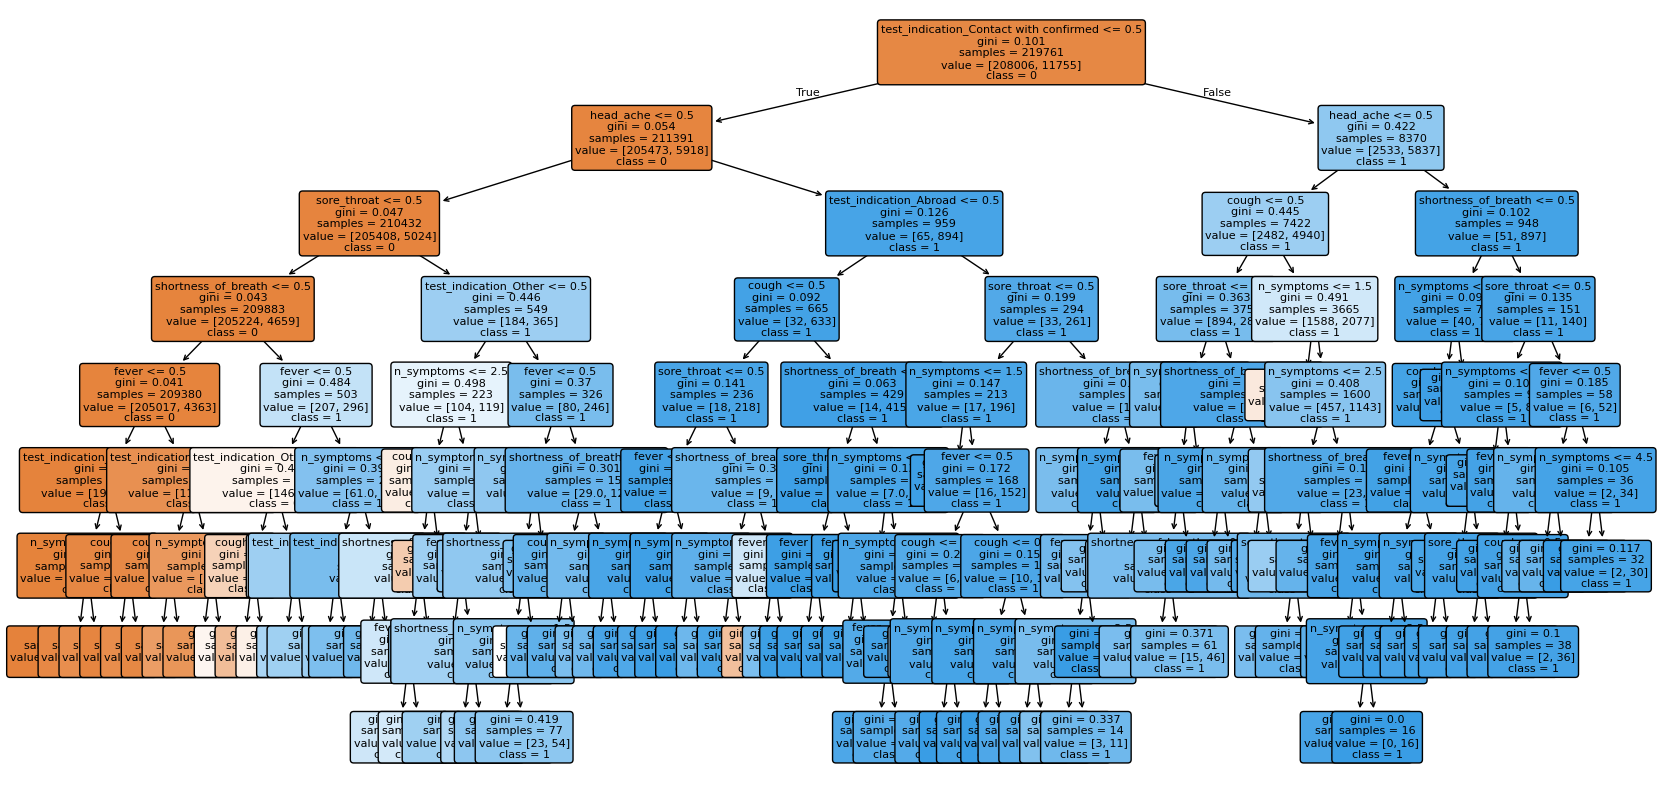

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)


from sklearn.tree import plot_tree

import matplotlib.pyplot as plt

plt.figure(figsize=(20,10))

plot_tree(
    dtc,

    filled=True,

    feature_names=X_train.columns,

    class_names=[str(c) for c in dtc.classes_],

    rounded=True,

    fontsize=8
)

plt.show()


# Evaluate

- Is accuracy the right metric to evaluate the model? Are inaccuracies correctly penalized in the accuracy metric?
- Which dataset should you choose to evaluate the model? Validation or Test?
- What other metric is relevant in our context?
- For benchmarking everyone’s results we will stick to ROC-AUC score as a metric.

In [ ]:
print('Accuracy :', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))
print('F1:', f1_score(y_test, y_pred))
print('ROC AUC  :', roc_auc_score(y_test, y_prob))

from sklearn.metrics import classification_report

y_pred = dtc.predict(X_test)

print(classification_report(y_test, y_pred))

#Bad at recall of positives
#want to prioritise catching positives (1) over false negatives

Accuracy : 0.967583407655485
Precision: 0.7918346774193549
Recall: 0.5345355563116706
F1: 0.6382287223237864
ROC AUC  : 0.8945129560868696
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     52002
           1       0.79      0.53      0.64      2939

    accuracy                           0.97     54941
   macro avg       0.88      0.76      0.81     54941
weighted avg       0.96      0.97      0.96     54941



              precision    recall  f1-score   support

           0       0.97      0.99      0.98     52002
           1       0.79      0.53      0.64      2939

    accuracy                           0.97     54941
   macro avg       0.88      0.76      0.81     54941
weighted avg       0.96      0.97      0.96     54941



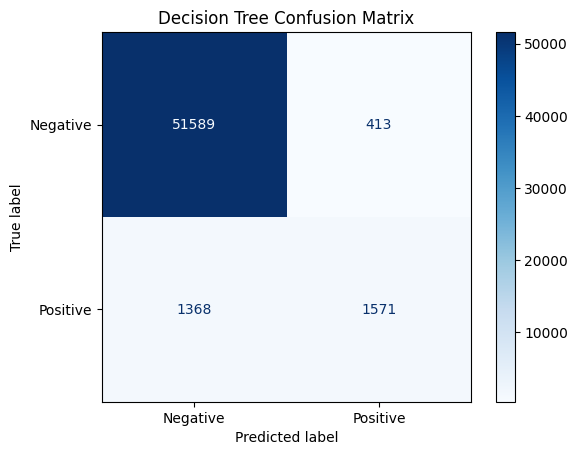

In [ ]:
from sklearn.metrics import classification_report

y_pred = dtc.predict(X_test)

print(classification_report(y_test, y_pred))

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=['Negative', 'Positive']

)

disp.plot(cmap='Blues')

plt.title('Decision Tree Confusion Matrix')

plt.show()


In [ ]:
'''
The model identified only 53% of the people who were actually positive.
Put another way, of 2,939 actual positives:
it correctly detected 1,571
it missed 1,368
so it's missing roughly 47% of the positive cases
 Correctly identified 1571 positive (1), 1358 were identified as negative when actually positive.
We want to improve this so catch more true positives.'''

"\nThe model identified only 53% of the people who were actually positive.\nPut another way, of 2,939 actual positives:\nit correctly detected 1,571\nit missed 1,368\nso it's missing roughly 47% of the positive cases\n Correctly identified 1571 positive (1), 1358 were identified as negative when actually positive.\nWe want to improve this so catch more true positives."

In [ ]:
#improvement with class_weight='balanced'
dtc = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42)
dtc.fit(X_train, y_train)

y_pred = dtc.predict(X_test)
y_prob = dtc.predict_proba(X_test)[:, 1]

print('Accuracy :', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))
print('F1:', f1_score(y_test, y_pred))
print('ROC AUC  :', roc_auc_score(y_test, y_prob))

from sklearn.metrics import classification_report

y_pred = dtc.predict(X_test)

print(classification_report(y_test, y_pred))

#has improved recall

Accuracy : 0.8933219271582242
Precision: 0.3088697017268446
Recall: 0.8033344675059544
F1: 0.44618728148918074
ROC AUC  : 0.8945130018882332
              precision    recall  f1-score   support

           0       0.99      0.90      0.94     52002
           1       0.31      0.80      0.45      2939

    accuracy                           0.89     54941
   macro avg       0.65      0.85      0.69     54941
weighted avg       0.95      0.89      0.91     54941



              precision    recall  f1-score   support

           0       0.99      0.90      0.94     52002
           1       0.31      0.80      0.45      2939

    accuracy                           0.89     54941
   macro avg       0.65      0.85      0.69     54941
weighted avg       0.95      0.89      0.91     54941



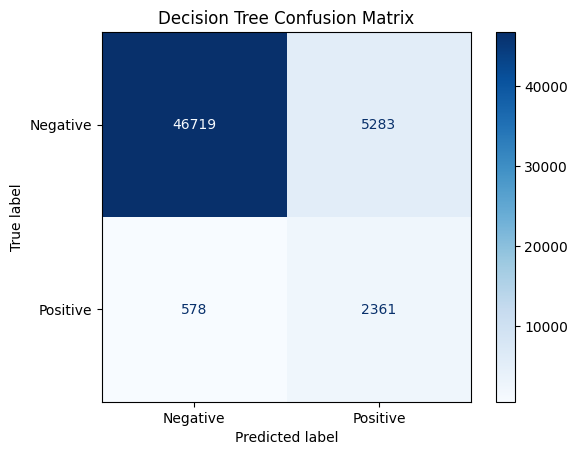

In [ ]:
from sklearn.metrics import classification_report

y_pred = dtc.predict(X_test)

print(classification_report(y_test, y_pred))

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=['Negative', 'Positive']

)

disp.plot(cmap='Blues')

plt.title('Decision Tree Confusion Matrix')

plt.show()


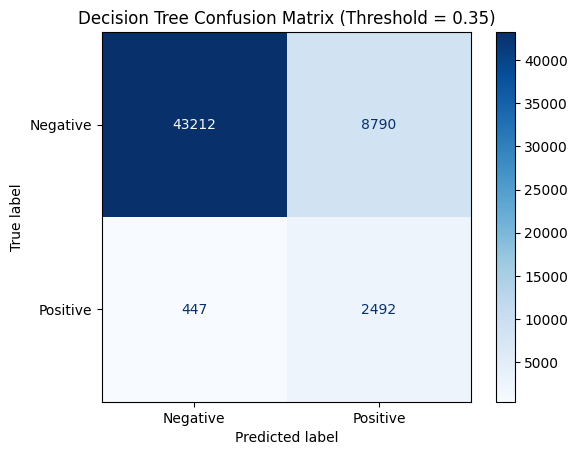

              precision    recall  f1-score   support

           0       0.99      0.83      0.90     52002
           1       0.22      0.85      0.35      2939

    accuracy                           0.83     54941
   macro avg       0.61      0.84      0.63     54941
weighted avg       0.95      0.83      0.87     54941



In [ ]:
'''this is to try a decision tree with a threshold of 0.35 after running LightGBM and
finding the threshold of 0.35 worked well for that
'''
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# Get predicted probabilities for positive class
y_prob_dtc = dtc.predict_proba(X_test)[:, 1]

# Apply threshold of 0.35
y_pred_dtc_035 = (y_prob_dtc >= 0.35).astype(int)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_dtc_035)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negative', 'Positive']
)

disp.plot(cmap='Blues')
plt.title('Decision Tree Confusion Matrix (Threshold = 0.35)')
plt.show()

# Classification report
print(classification_report(y_test, y_pred_dtc_035))

In [ ]:
'''Explore with SHap'''

%pip install shap
import shap


# Create a SHAP explainer for the trained decision tree
explainer = shap.TreeExplainer(dtc)

# Select a sample of observations to explain
X_sample = X_test.sample(
    n=min(500, len(X_test)),
    random_state=42
)

# Calculate SHAP values
shap_values = explainer(X_sample)

print("SHAP values shape:", shap_values.values.shape)


SHAP values shape: (500, 9, 2)


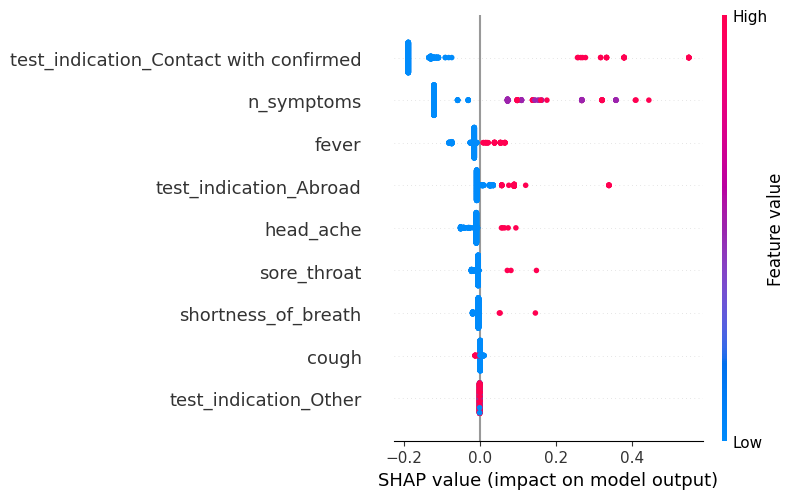

In [ ]:

import numpy as np

# Find the index of the positive class
positive_class = (
    list(dtc.classes_).index(1)
    if 1 in dtc.classes_
    else list(dtc.classes_).index('positive')
)

# Select positive-class SHAP values if both classes are present
if shap_values.values.ndim == 3:
    positive_shap = shap_values[:, :, positive_class]
else:
    positive_shap = shap_values

# Plot feature contributions
shap.summary_plot(
    positive_shap.values,
    X_sample,
    feature_names=X_sample.columns
)


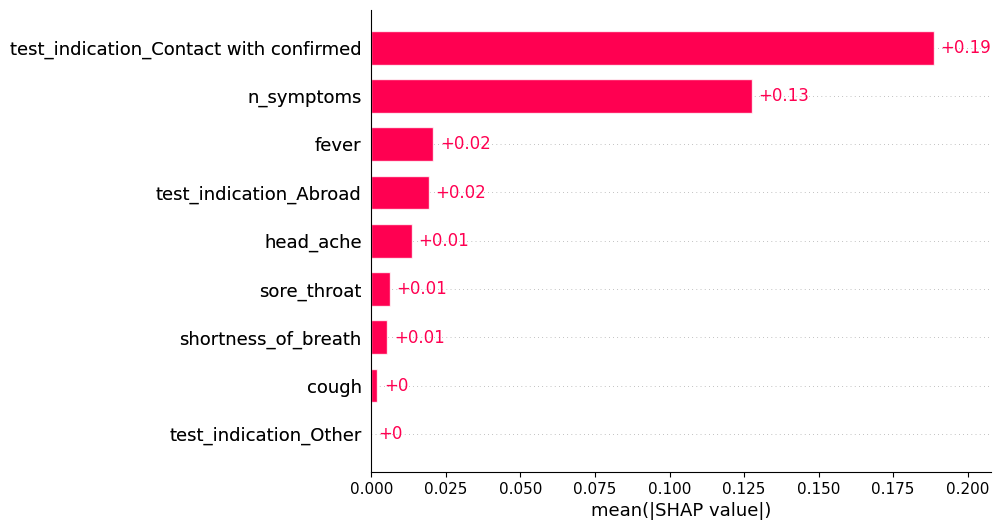

In [ ]:

shap.plots.bar(positive_shap, max_display=10)


# Report

- With the metric chosen, report your result on the test dataset.
- How will you select the threshold for your model above which model score will be interpreted as a prediction of positive diagnosis.

# Extras

- Dimensionality Reduction for fun: Can you reduce the dimension to just 2 dimensions and check if the inputs corresponding to different classes belong to different clusters? Try using t-SNE or UMAP for that purpose.
- Collaborate with Ensemble: Can you combine other models?

In [ ]:
'''
Priority	Issue	Recommendation
HighTest set used during development	Create a separate validation set
High	Reporting bias	Compare models with and without potentially biased symptoms
High	False negatives	Investigate classification thresholds
Medium	Age and gender excluded	Test whether including them improves performance
Medium	Random split	Compare against a chronological split
Low	Decision tree visualisation	Limit displayed depth to make it r	eadable
'''

'\nPriority\tIssue\tRecommendation\nHighTest set used during development\tCreate a separate validation set\nHigh\tReporting bias\tCompare models with and without potentially biased symptoms\nHigh\tFalse negatives\tInvestigate classification thresholds\nMedium\tAge and gender excluded\tTest whether including them improves performance\nMedium\tRandom split\tCompare against a chronological split\nLow\tDecision tree visualisation\tLimit displayed depth to make it r\teadable\n'

Trying LightGBM

In [ ]:



#Try LightGBM on the encoded_df

import lightgbm as lgb

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# ---- make a validation set out of the TRAIN split (test stays untouched) ----
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

lgb_base = lgb.LGBMClassifier(
    class_weight='balanced',
    random_state=42,
    verbose=-1
)
#for computational efficiency chose smaller parameter grid
#decision
param_grid_lgb = {
    'n_estimators': [50, 100],
    'num_leaves': [15, 31],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8],
    'subsample_freq': [1],
    'colsample_bytree': [0.8],
    'reg_alpha': [0, 0.1],
    'reg_lambda': [1.0]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
#optismise for recall
#decision
random_search_lgb = RandomizedSearchCV(
    estimator=lgb_base,
    param_distributions=param_grid_lgb,
    n_iter=15,
    scoring='recall',
    cv=cv,
    random_state=42,
    n_jobs=2,
    verbose=1
)

random_search_lgb.fit(X_tr, y_tr)

lgb_best = random_search_lgb.best_estimator_

print("Best Parameters:", random_search_lgb.best_params_)
print("Best CV Recall:", random_search_lgb.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best Parameters: {'subsample_freq': 1, 'subsample': 0.8, 'reg_lambda': 1.0, 'reg_alpha': 0, 'num_leaves': 15, 'n_estimators': 50, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV Recall: 0.8185861413688962


Evaluate model

In [ ]:
#used best parameters

# Best model from RandomizedSearchCV
lgb_best = random_search_lgb.best_estimator_

# Predictions  (on VALIDATION, not test)
y_pred_lgb = lgb_best.predict(X_val)
y_prob_lgb = lgb_best.predict_proba(X_val)[:, 1]

# Evaluation on validation, not test
print('Accuracy :', accuracy_score(y_val, y_pred_lgb))
print('Precision:', precision_score(y_val, y_pred_lgb))
print('Recall   :', recall_score(y_val, y_pred_lgb))
print('F1       :', f1_score(y_val, y_pred_lgb))
print('ROC AUC  :', roc_auc_score(y_val, y_prob_lgb))

print(classification_report(y_val, y_pred_lgb))

Accuracy : 0.874502309284918
Precision: 0.2758181045473863
Recall   : 0.8281582305401957
F1       : 0.41381509032943675
ROC AUC  : 0.8990957453845869
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     41602
           1       0.28      0.83      0.41      2351

    accuracy                           0.87     43953
   macro avg       0.63      0.85      0.67     43953
weighted avg       0.95      0.87      0.90     43953



Find best threshold

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
#try different thresholds (on VALIDATION)
thresholds = [0.2, 0.3, 0.35, 0.4, 0.5, 0.6]

for threshold in thresholds:

    y_pred_threshold = (y_prob_lgb >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")

    print("Precision:",
          precision_score(y_val, y_pred_threshold))

    print("Recall:",
          recall_score(y_val, y_pred_threshold))

    print("F1:",
          f1_score(y_val, y_pred_threshold))


Threshold: 0.2
Precision: 0.22484943118447467
Recall: 0.8575074436410038
F1: 0.35627816559158787

Threshold: 0.3
Precision: 0.22484943118447467
Recall: 0.8575074436410038
F1: 0.35627816559158787

Threshold: 0.35
Precision: 0.22484943118447467
Recall: 0.8575074436410038
F1: 0.35627816559158787

Threshold: 0.4
Precision: 0.22484943118447467
Recall: 0.8575074436410038
F1: 0.35627816559158787

Threshold: 0.5
Precision: 0.2758181045473863
Recall: 0.8281582305401957
F1: 0.41381509032943675

Threshold: 0.6
Precision: 0.40465431540894714
Recall: 0.761803487877499
F1: 0.5285524568393094


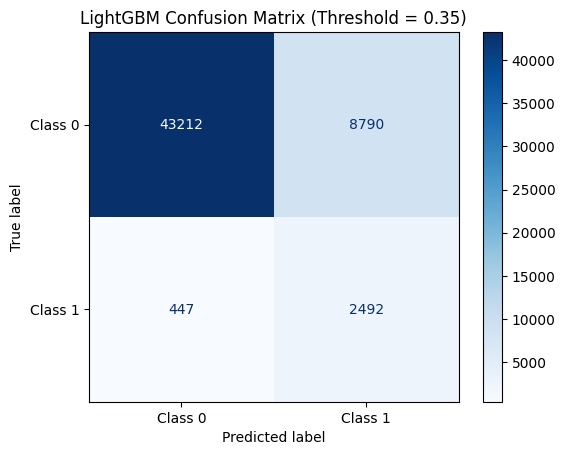

              precision    recall  f1-score   support

           0       0.99      0.83      0.90     52002
           1       0.22      0.85      0.35      2939

    accuracy                           0.83     54941
   macro avg       0.61      0.84      0.63     54941
weighted avg       0.95      0.83      0.87     54941

Validation ROC AUC (on probabilities): 0.8990957453845869


In [ ]:
#used threshold of 0.35
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

chosen_threshold = 0.35

# Predictions on TEST
y_prob_test = lgb_best.predict_proba(X_test)[:, 1]
y_pred_lgb_035 = (y_prob_test >= chosen_threshold).astype(int)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_lgb_035)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Class 0', 'Class 1']
)

disp.plot(cmap='Blues')
plt.title(f'LightGBM Confusion Matrix (Threshold = {chosen_threshold})')
plt.show()

print(classification_report(y_test, y_pred_lgb_035))
print("Validation ROC AUC (on probabilities):", roc_auc_score(y_val, y_prob_lgb))

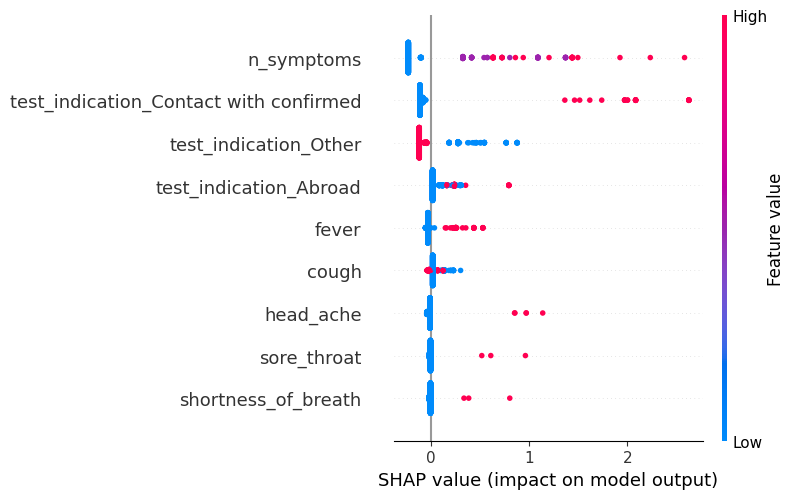

In [ ]:
#Shap on LightGBM
import shap
#
explainer_lgb = shap.TreeExplainer(lgb_best)

#
X_sample = X_test.sample(n=min(500, len(X_test)), random_state=42)
shap_values = explainer_lgb(X_sample)

#
positive_class = (
    list(lgb_best.classes_).index(1)
    if 1 in lgb_best.classes_
    else list(lgb_best.classes_).index('positive')
)

#

if shap_values.values.ndim == 3:
    positive_shap = shap_values[:, :, positive_class]
else:
    positive_shap = shap_values

#
shap.summary_plot(
    positive_shap.values,
    X_sample,
    feature_names=X_sample.columns)

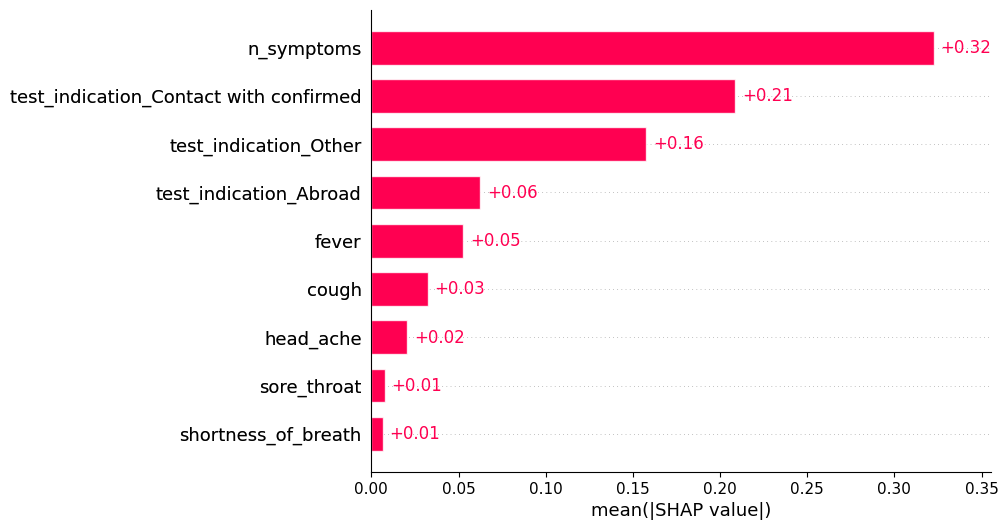

In [ ]:
shap.plots.bar(positive_shap, max_display=10)

In [ ]:

print("lgb_best:", 'lgb_best' in dir())

# ---------- Model B: SMOTE model ----------
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
import lightgbm as lgb

lgb_pipe = ImbPipeline(steps=[
    ('smote', SMOTE(sampling_strategy=0.333, random_state=42)),
    ('clf',   lgb.LGBMClassifier(class_weight=None, random_state=42, verbose=-1))
])

random_search_lgb_smote = RandomizedSearchCV(
    estimator=lgb_pipe,
    param_distributions={f'clf__{k}': v for k, v in param_grid_lgb.items()},
    n_iter=15, scoring='recall',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state=42, n_jobs=2, verbose=1
)
random_search_lgb_smote.fit(X_tr, y_tr)          # ORIGINAL unsmoted data
lgb_best_smote = random_search_lgb_smote.best_estimator_   # <-- this line creates it
print("lgb_best_smote ready:", type(lgb_best_smote))

lgb_best: True
Fitting 5 folds for each of 15 candidates, totalling 75 fits
lgb_best_smote ready: <class 'imblearn.pipeline.Pipeline'>


In [ ]:
import shap, pandas as pd

assert 'lgb_best' in dir(),       "Run your original model cell first (lgb_best)."
assert 'lgb_best_smote' in dir(), "Run the SMOTE model cell first (lgb_best_smote)."

# Pull the fitted classifier out of the pipeline
clf_smote = (lgb_best_smote.named_steps['clf']
             if hasattr(lgb_best_smote, 'named_steps')
             else lgb_best_smote)

explainer_orig  = shap.TreeExplainer(lgb_best)
explainer_smote = shap.TreeExplainer(clf_smote)

X_sample = X_test.sample(n=min(500, len(X_test)), random_state=42)
sv_orig  = explainer_orig(X_sample)
sv_smote = explainer_smote(X_sample)

pos_idx = list(lgb_best.classes_).index(1)
orig_pos  = sv_orig[:, :, pos_idx]  if sv_orig.values.ndim  == 3 else sv_orig
smote_pos = sv_smote[:, :, pos_idx] if sv_smote.values.ndim == 3 else sv_smote

rank_orig  = pd.Series(abs(orig_pos.values).mean(0),  index=X_sample.columns)
rank_smote = pd.Series(abs(smote_pos.values).mean(0), index=X_sample.columns)

comparison = pd.DataFrame({
    'mean_abs_shap_classweight': rank_orig,
    'mean_abs_shap_SMOTE':       rank_smote,
}).sort_values('mean_abs_shap_SMOTE', ascending=False)
print(comparison.head(15).round(4))

                                        mean_abs_shap_classweight  \
test_indication_Contact with confirmed                     0.2088   
n_symptoms                                                 0.3226   
test_indication_Other                                      0.1577   
head_ache                                                  0.0206   
fever                                                      0.0528   
cough                                                      0.0325   
test_indication_Abroad                                     0.0625   
sore_throat                                                0.0078   
shortness_of_breath                                        0.0066   

                                        mean_abs_shap_SMOTE  
test_indication_Contact with confirmed               0.5852  
n_symptoms                                           0.4361  
test_indication_Other                                0.3427  
head_ache                                            0.1499  

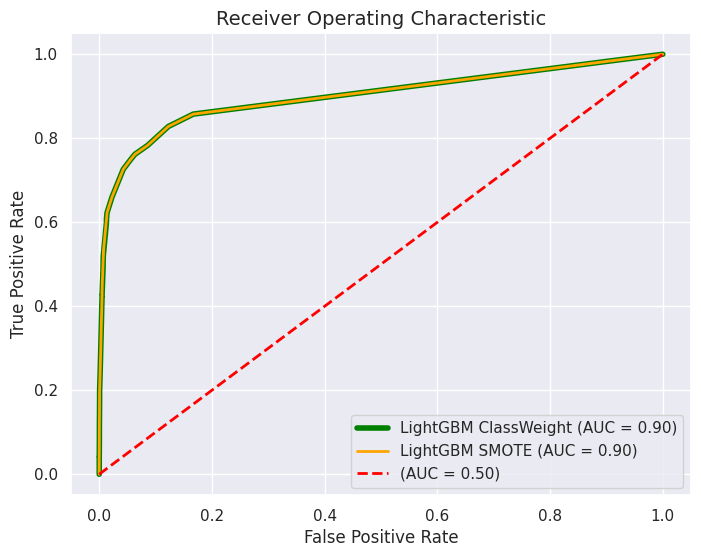

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score

#
sns.set_theme(style="darkgrid")

plt.figure(figsize=(8, 6))

# --- Model 1: class_weight model ---
fpr_1, tpr_1, _ = roc_curve(y_val, y_prob_lgb)
auc_1 = roc_auc_score(y_val, y_prob_lgb)
plt.plot(fpr_1, tpr_1, label=f'LightGBM ClassWeight (AUC = {auc_1:.2f})', color='green', linewidth=4)

# --- Model 2: SMOTE model ---
y_prob_smote = lgb_best_smote.predict_proba(X_val)[:, 1]
fpr_2, tpr_2, _ = roc_curve(y_val, y_prob_smote)
auc_2 = roc_auc_score(y_val, y_prob_smote)
plt.plot(fpr_2, tpr_2, label=f'LightGBM SMOTE (AUC = {auc_2:.2f})', color='orange', linewidth=2)

# --- Baseline: Random Guess ---
plt.plot([0, 1], [0, 1], color='red', linestyle='--', linewidth=2, label='(AUC = 0.50)')

# Formatting
plt.title('Receiver Operating Characteristic', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)

# Place the legend (your image has it in the bottom right)
plt.legend(loc='lower right')

plt.show()